# Session 2 — Under the Hood: A Confident Tour of the Transformer

**Series:** *Chasing "I Don't Know" in Modern Language Models*

**Session length:** ~60 min.
**Compute:** CPU sufficient; GPU optional.
**Prerequisite:** Sessions 0 and 1.

## Framing

If Session 1 was *"what a model does,"* Session 2 is *"what a model **is**"* — but at a level a working scientist can hold in their head, not at the level of a machine-learning course. By the end of this session you will be able to hear the sentence

> *"we used a 24-layer transformer with 16 attention heads and grouped-query attention, and we manipulated the KV cache to force early stopping"*

and know what each phrase means and roughly why someone would care.

That's the goal. Not to reproduce the math — to remove the intimidation. This is the session where a reader who is a working scientist stops feeling like an outsider to the LLM literature.

---

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os

from workshop_utils import (
    load_model_and_tokenizer,
    pick_device,
    pick_dtype,
    set_all_seeds,
    human_bytes,
)

os.makedirs("figures", exist_ok=True)

device = pick_device()
dtype = pick_dtype(device)

set_all_seeds(0)
tokenizer, model = load_model_and_tokenizer(
    "Qwen/Qwen2.5-1.5B-Instruct",
    device=device,
    dtype=dtype,
)

Loading Qwen/Qwen2.5-1.5B-Instruct @ main onto cuda as torch.bfloat16...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  loaded: 28 layers, hidden 1536, vocab 151936


## Part 1 — The full pipeline in one picture

Text → **tokens** → **embeddings** → *N* stacked **transformer layers** → **final projection** → **logits** → **sampling** → next token.

Every arrow is one concept. Each subsequent part unpacks one arrow.

Let's draw this diagram programmatically so it's part of the notebook.

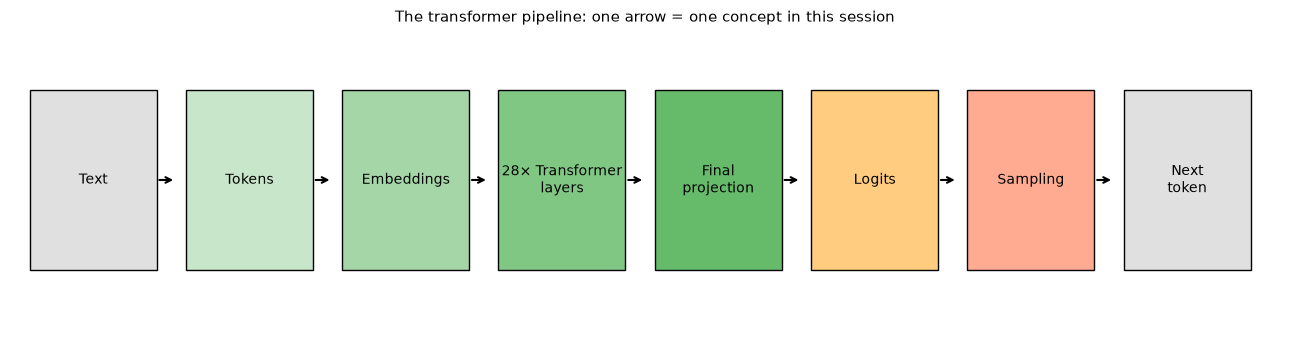

In [3]:
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.axis("off")

boxes = [
    ("Text",       0, "#e0e0e0"),
    ("Tokens",     1, "#c8e6c9"),
    ("Embeddings", 2, "#a5d6a7"),
    (f"{model.config.num_hidden_layers}× Transformer\nlayers", 3, "#81c784"),
    ("Final\nprojection", 4, "#66bb6a"),
    ("Logits",     5, "#ffcc80"),
    ("Sampling",   6, "#ffab91"),
    ("Next\ntoken",7, "#e0e0e0"),
]

for name, i, color in boxes:
    x = i * 1.6
    ax.add_patch(plt.Rectangle((x, 0.4), 1.3, 1.2, facecolor=color, edgecolor="black"))
    ax.text(x + 0.65, 1.0, name, ha="center", va="center", fontsize=10)
    if i < len(boxes) - 1:
        ax.annotate("", xy=(x + 1.5, 1.0), xytext=(x + 1.3, 1.0),
                    arrowprops=dict(arrowstyle="->", lw=1.5))

ax.set_xlim(-0.2, len(boxes) * 1.6)
ax.set_ylim(0, 2)
ax.set_title("The transformer pipeline: one arrow = one concept in this session", fontsize=11)
plt.tight_layout()
plt.savefig("figures/session2_pipeline.png", dpi=120)
plt.show()

We'll walk left-to-right through this diagram, spending one section on each arrow.

---

## Part 2 — Embeddings: tokens become vectors

The tokenizer gives us integers. The model can't work with integers directly — it works with vectors. The **embedding layer** is a lookup table: each token ID → a vector of `hidden_size` numbers.

For Qwen2.5-1.5B, `hidden_size` is:

In [4]:
print(f"Hidden size: {model.config.hidden_size}")
print(f"Vocab size:  {model.config.vocab_size}")
print(f"Embedding table shape: {model.get_input_embeddings().weight.shape}")

Hidden size: 1536
Vocab size:  151936
Embedding table shape: torch.Size([151936, 1536])


So the embedding table is `vocab_size × hidden_size` — about 150,000 tokens × 1,536 dimensions.

**The vectors are learned.** Similar tokens end up with similar vectors. That's why the model "knows" that Paris is more like London than like breadfruit — the vectors are close in high-dimensional space, and the network's downstream computations exploit that.

Let's demonstrate:

In [5]:
def token_vector(text):
    """Get the embedding vector for a single-token text.
    If the text tokenizes to multiple tokens, we take the first one and warn.
    """
    
    ids = tokenizer.encode(text, add_special_tokens=False)
    if len(ids) != 1:
        print(f"  note: {text!r} tokenizes to {len(ids)} tokens; using the first")
    return model.get_input_embeddings().weight[ids[0]].detach().cpu().float()


def cosine(a, b):
    return float((a @ b) / (a.norm() * b.norm() + 1e-12))


words = [" Paris", " London", " Warsaw", " breadfruit", " Tuesday"]
vectors = {w.strip(): token_vector(w) for w in words}

print(f"\nCosine similarities between token embeddings:\n")
names = list(vectors.keys())
print(f"{'':11s}" + "".join(f"{n:>12s}" for n in names))
for a in names:
    row = f"{a:>11s}"
    for b in names:
        row += f"{cosine(vectors[a], vectors[b]):>12.3f}"
    print(row)

  note: ' breadfruit' tokenizes to 2 tokens; using the first

Cosine similarities between token embeddings:

                  Paris      London      Warsaw  breadfruit     Tuesday
      Paris       1.000       0.391       0.295       0.032       0.067
     London       0.391       1.000       0.221       0.019       0.067
     Warsaw       0.295       0.221       1.000       0.107       0.116
 breadfruit       0.032       0.019       0.107       1.000       0.071
    Tuesday       0.067       0.067       0.116       0.071       1.000


The three capitals cluster (higher pairwise cosine similarity than any of them to `"breadfruit"` or `"Tuesday"`). The vectors *encode* something about semantic similarity, learned from co-occurrence patterns in the training corpus.

**Caveat, explicitly.** This cosine-similarity view is *suggestive*, not definitive. The model uses the full embedding for downstream computation; word similarities in the raw embedding table are a first-order effect, not the whole story. Some published work ([Gao et al., "SimCSE," 2021](https://arxiv.org/abs/2104.08821), among others) has shown that raw embedding cosines can be misleading in isolation. But for our purposes, the demo makes the abstract idea *"tokens are vectors"* concrete.

---

## Part 3 — Attention, in plain English

**Attention is how the model looks back at earlier tokens to decide what to do next.**

The intuition, in one line: at each position, the model asks *"for this token I'm generating, which earlier tokens matter most?"* — and mixes information from those earlier tokens accordingly.

That's it. Multiple attention **heads** mean the model does this several ways in parallel — one head might be tracking syntactic dependencies, another might be tracking who-said-what in a dialogue, another might be tracking factual entities. In practice most individual heads are not cleanly interpretable, but the collective effect is *"the model can flexibly reference any part of its context when generating the next token."*

Let's look at the model's config for the numbers:

In [6]:
cfg = model.config
print(f"Number of attention heads:       {cfg.num_attention_heads}")
if hasattr(cfg, "num_key_value_heads"):
    print(f"Number of key/value heads:       {cfg.num_key_value_heads}  (grouped-query attention if < num_attention_heads)")
print(f"Hidden size per head:            {cfg.hidden_size // cfg.num_attention_heads}")
print(f"Number of transformer layers:    {cfg.num_hidden_layers}")

Number of attention heads:       12
Number of key/value heads:       2  (grouped-query attention if < num_attention_heads)
Hidden size per head:            128
Number of transformer layers:    28


Now let's actually extract attention weights from one head and one layer, and visualize them.

**Big caveat, stated once and loudly:** individual attention heads are *not usually cleanly interpretable*, and reading meaning into any one heatmap is a well-known trap in the field. This demo is for showing *shape* — that attention is real, measurable, and reference-based — not for reading meaning into a specific head.

In [3]:
sentence = "Marie Curie won two Nobel Prizes. She was born in Warsaw."
inputs = tokenizer(sentence, return_tensors="pt").to(device)

# Ask the model to return attention weights.
# SDPA/flash-attention kernels never materialize attention probabilities,
# so output_attentions requires the "eager" backend — switch temporarily.
original_impl = model.config._attn_implementation
model.set_attn_implementation("eager")
with torch.no_grad():
    out = model(**inputs, output_attentions=True)
model.set_attn_implementation(original_impl)

# out.attentions is a tuple of length num_layers, each of shape
# (batch, num_heads, seq_len, seq_len)
attentions = out.attentions
print(f"Number of layers with attention: {len(attentions)}")
print(f"Shape of one attention tensor:   {tuple(attentions[0].shape)}  (batch, heads, seq, seq)")

Number of layers with attention: 28
Shape of one attention tensor:   (1, 12, 16, 16)  (batch, heads, seq, seq)


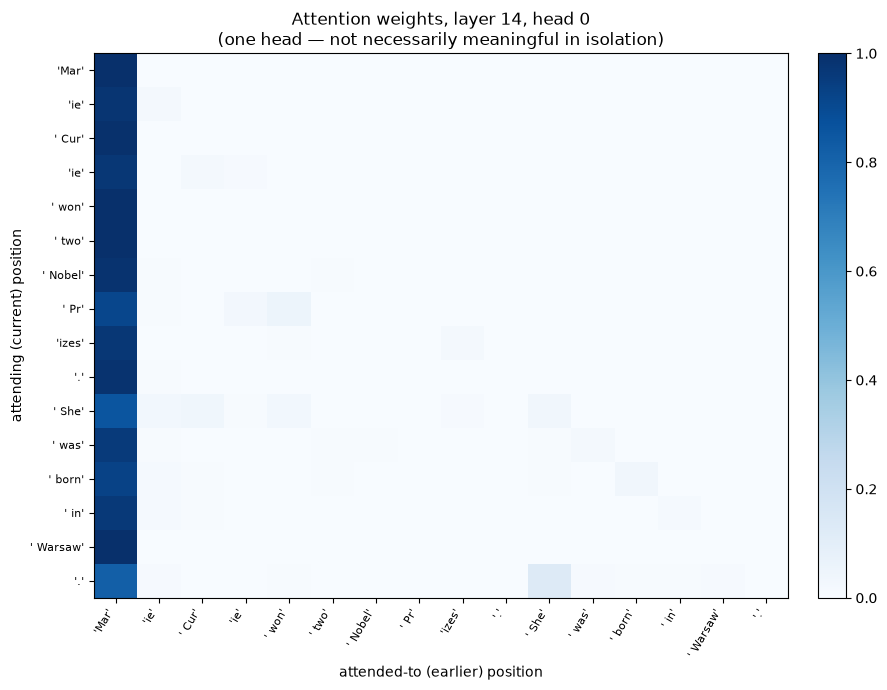

In [4]:
# Visualize one head from a middle layer
layer_idx = len(attentions) // 2
head_idx = 0

attn = attentions[layer_idx][0, head_idx].detach().cpu().float().numpy()
tokens = [tokenizer.decode([t]) for t in inputs.input_ids[0].tolist()]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(attn, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(tokens)))
ax.set_yticks(range(len(tokens)))
ax.set_xticklabels([repr(t)[:10] for t in tokens], rotation=60, ha="right", fontsize=8)
ax.set_yticklabels([repr(t)[:10] for t in tokens], fontsize=8)
ax.set_xlabel("attended-to (earlier) position")
ax.set_ylabel("attending (current) position")
ax.set_title(f"Attention weights, layer {layer_idx}, head {head_idx}\n"
             f"(one head — not necessarily meaningful in isolation)")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("figures/session2_attention_heatmap.png", dpi=120)
plt.show()

**How to read this.** Each row is one token's *attention distribution over earlier tokens*. The lower-triangular pattern is enforced by the causal mask — a token can only attend to itself and earlier tokens (never to the future).

Rows near the top attend mostly to themselves (row 0 can only attend to itself). Rows lower down show broader attention patterns — the head is "looking back" at earlier tokens with varying intensity.

What you should *not* do: pick a bright cell and declare "this head is doing coreference resolution!" without a lot more evidence. What you *can* do: appreciate that the model has, in fact, a rich internal mechanism for cross-referencing tokens in its context.

Deliberately not covered here: the query/key/value math, softmax over dot products, positional encodings. Pointed to for the curious: [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) is the standard-issue accessible explainer.

---

## Part 4 — The MLP block: where the model computes

After attention gathers information from context, the **MLP** (multi-layer perceptron) block transforms it. Every transformer layer alternates: attention (mix in context) → MLP (compute on the mix) → attention → MLP → …

The MLP is where a lot of the model's **knowledge** is thought to live — recent interpretability work has traced specific facts to specific MLP neurons in specific layers.

For the workshop's purposes, the useful mental model is:

> **Attention decides what to look at; MLP decides what to do with what it looked at.**

Let's confirm the MLP is where most of the weight sits.

In [5]:
def parameter_breakdown(model):
    """Group the model's parameters by rough function."""
    buckets = {
        "embedding": 0,
        "attention": 0,
        "MLP": 0,
        "output_projection": 0,
        "layer_norms": 0,
        "other": 0,
    }
    for name, p in model.named_parameters():
        n = p.numel()
        lname = name.lower()
        if "embed" in lname:
            buckets["embedding"] += n
        elif "mlp" in lname or "feed_forward" in lname or "fc" in lname:
            buckets["MLP"] += n
        elif any(k in lname for k in ["self_attn", "attention", ".attn.", "q_proj", "k_proj", "v_proj", "o_proj"]):
            buckets["attention"] += n
        elif "lm_head" in lname or "output_proj" in lname:
            buckets["output_projection"] += n
        elif "norm" in lname or "ln_" in lname:
            buckets["layer_norms"] += n
        else:
            buckets["other"] += n
    return buckets


bd = parameter_breakdown(model)
total = sum(bd.values())
print(f"Total parameters: {total / 1e6:.1f}M\n")
print(f"{'component':<20s} {'params':>12s} {'%':>7s}")
for name, count in sorted(bd.items(), key=lambda x: -x[1]):
    print(f"{name:<20s} {count / 1e6:>10.1f}M {100 * count / total:>6.1f}%")

Total parameters: 1543.7M

component                  params       %
MLP                      1156.1M   74.9%
embedding                 233.4M   15.1%
attention                 154.2M   10.0%
layer_norms                 0.0M    0.0%
output_projection           0.0M    0.0%
other                       0.0M    0.0%


The MLP typically dominates — usually 50–70% of parameters for modern models. When people say "the model's knowledge lives in the MLP," this is quantitatively where they're pointing.

Let's also make this visible as a chart:

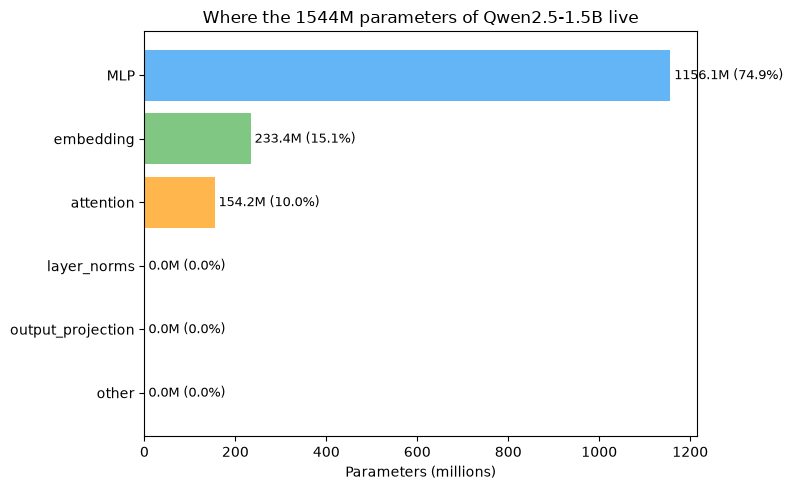

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
components = sorted(bd.items(), key=lambda x: -x[1])
names = [n for n, _ in components]
vals = [v / 1e6 for _, v in components]
colors = ["#64b5f6", "#81c784", "#ffb74d", "#e57373", "#ba68c8", "#a1887f"]
bars = ax.barh(names, vals, color=colors[:len(names)])
for bar, v in zip(bars, vals):
    ax.text(v, bar.get_y() + bar.get_height() / 2,
            f" {v:.1f}M ({100*v/(total/1e6):.1f}%)", va="center", fontsize=9)
ax.set_xlabel("Parameters (millions)")
ax.set_title(f"Where the {total/1e6:.0f}M parameters of Qwen2.5-1.5B live")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("figures/session2_param_breakdown.png", dpi=120)
plt.show()

---

## Part 5 — The residual stream

Each transformer layer **adds to** a running representation of the sequence, rather than replacing it. This running representation is called the **residual stream**. Layer 1 adds a small perturbation to the embeddings; layer 2 adds another; and so on for all *N* layers. At the end, the accumulated stream is projected to logits.

Why this matters: the model builds understanding **incrementally and additively**. Earlier layers set up primitive features; later layers refine them. And crucially, you can "read out" a partial answer from the middle of the network — a technique called the **logit lens** — and see how the model's guess about the next token evolves through depth.

Let's do that.

In [7]:
def logit_lens(model, tokenizer, prompt, layers_to_probe=None):
    """Extract the hidden state at each requested layer, project it through
    the final unembedding matrix, and return the top-1 token prediction.

    This works cleanly on many but not all models — depends on whether the
    final layer norm is applied 'pre' or 'post' in the model's architecture.
    On Qwen it works well enough for illustration.
    """
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    with torch.no_grad():
        out = model(**inputs, output_hidden_states=True)

    hidden_states = out.hidden_states  # tuple of (num_layers+1,) tensors
    # hidden_states[0] is the embedding output; hidden_states[i] is the
    # output of transformer layer i.

    if layers_to_probe is None:
        layers_to_probe = list(range(len(hidden_states)))

    # The final unembedding matrix (a.k.a. lm_head)
    lm_head = model.get_output_embeddings()

    results = []
    # Try to find the final layer norm — most Llama-family models have one
    final_norm = None
    for attr in ["norm", "final_layer_norm", "ln_f"]:
        if hasattr(model.model, attr):
            final_norm = getattr(model.model, attr)
            break

    for layer_idx in layers_to_probe:
        h = hidden_states[layer_idx][0, -1, :]  # last position, first batch
        if final_norm is not None:
            h = final_norm(h)
        logits = lm_head(h.to(next(lm_head.parameters()).dtype))
        top_prob, top_id = torch.topk(logits.float().softmax(dim=-1), k=1)
        results.append({
            "layer": layer_idx,
            "top_token": tokenizer.decode([int(top_id.item())]),
            "top_prob": float(top_prob.item()),
        })
    return results

In [8]:
n_layers = model.config.num_hidden_layers
probe_layers = list(range(0, n_layers + 1, max(1, n_layers // 10)))

for prompt in [
    "The capital of France is",
    "The capital of Kiribati is",
]:
    print(f"\nPrompt: {prompt!r}")
    print(f"{'layer':>6} | {'top-1 token':>16} | {'prob':>7}")
    print("-" * 40)
    for row in logit_lens(model, tokenizer, prompt, layers_to_probe=probe_layers):
        print(f"{row['layer']:>6d} | {row['top_token']!r:>16s} | {row['top_prob']:>7.3f}")


Prompt: 'The capital of France is'
 layer |      top-1 token |    prob
----------------------------------------
     0 |            ' is' |   1.000
     2 |             'nt' |   0.244
     4 |              's' |   0.192
     6 |            ' Ex' |   0.114
     8 |            '欢迎您' |   0.162
    10 |        ' secret' |   0.065
    12 |       ' located' |   0.315
    14 |       ' located' |   0.078
    16 |       ' located' |   0.057
    18 |       ' located' |   0.224
    20 |           '____' |   0.666
    22 |           '____' |   0.281
    24 |         ' Paris' |   0.781
    26 |         ' Paris' |   0.927
    28 |           ' the' |   0.259

Prompt: 'The capital of Kiribati is'
 layer |      top-1 token |    prob
----------------------------------------
     0 |            ' is' |   1.000
     2 |             'nt' |   0.205
     4 |              ',' |   0.196
     6 |            ' Ex' |   0.068
     8 |         ' known' |   0.046
    10 |       ' located' |   0.107
    12 |       '

**What to look for.** For a well-known fact (`"The capital of France is"`), you should see the top-1 prediction converge to the correct answer somewhere in the middle-to-late layers, with the probability rising sharply as depth increases. The model *becomes more confident of its answer as depth increases*, and you can watch it happen.

For an obscure or unknowable prompt (`"The capital of Kiribati is"`), commitment may happen later or not at all, and the top-1 through depth may bounce between plausible-looking candidates. Different models behave differently on this — Qwen2.5-1.5B may or may not know Tarawa depending on the checkpoint.

**Practical caveat.** Logit-lens results are cleaner on some models than others, and are known to be *biased* — the middle layers weren't trained to produce clean output distributions directly, so early-layer readouts can be systematically off. Treat the picture as qualitative.

---

## Part 6 — The KV cache

Every time you generate the next token, the model has to compute attention over *all* previous tokens. Naively, that would mean recomputing everything from scratch at each step — a quadratic cost in sequence length.

The **KV cache** is the engineering trick that makes this fast: the model saves the "keys" and "values" it already computed for earlier tokens, and reuses them when generating each new token. Only the newest token's computation is fresh.

**Consequences:**

1. Generation with a KV cache is roughly linear in output length rather than quadratic. This is why chat is snappy.
2. The KV cache **grows with the context**. For long contexts, it becomes the dominant memory cost — much bigger than the model weights themselves.
3. Because the KV cache is just a tensor sitting in memory, researchers can **manipulate it directly** — force a specific prefix, inject a token mid-stream, or truncate a hallucinated span. This is how the causal interventions in Session 4 (snowball fix) and Session 7 (suppress-the-suppression) will work.

Let's put concrete numbers on point 2.

In [9]:
def kv_cache_size(model, seq_len, batch_size=1, dtype=torch.bfloat16):
    """Estimate KV cache memory for a given context length."""
    cfg = model.config
    num_layers = cfg.num_hidden_layers
    hidden_size = cfg.hidden_size
    num_heads = cfg.num_attention_heads
    kv_heads = getattr(cfg, "num_key_value_heads", num_heads)
    head_dim = hidden_size // num_heads
    bytes_per_element = torch.tensor([], dtype=dtype).element_size()

    # 2 = one for keys, one for values
    total_bytes = 2 * num_layers * batch_size * seq_len * kv_heads * head_dim * bytes_per_element
    return total_bytes


print(f"KV cache size for Qwen2.5-1.5B at various context lengths:\n")
print(f"{'context length':>15s} | {'KV cache size':>18s}")
print("-" * 40)
for n in [100, 500, 1000, 4000, 32000, 128000]:
    print(f"{n:>15d} | {human_bytes(kv_cache_size(model, n)):>18s}")

# For reference, the model weights themselves:
weight_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
print(f"\nFor comparison, model weights: {human_bytes(weight_bytes)}")

KV cache size for Qwen2.5-1.5B at various context lengths:

 context length |      KV cache size
----------------------------------------
            100 |            2.73 MB
            500 |           13.67 MB
           1000 |           27.34 MB
           4000 |          109.38 MB
          32000 |          875.00 MB
         128000 |            3.42 GB

For comparison, model weights:   2.88 GB


At long context lengths, the KV cache dwarfs the model weights themselves. This is why long-context inference is expensive both in memory and in latency, and why techniques like grouped-query attention (fewer KV heads than attention heads) are so aggressively adopted in modern models.

---

## Part 7 — Layers and depth

Small models like Qwen2.5-1.5B have around 28 layers; larger models like Llama-3.1-70B have around 80; frontier models have more. Depth roughly tracks capability but with diminishing returns. Depth is also where most of the *computation* is — a forward pass through 80 layers takes longer than one through 28.

In [10]:
print(f"Model: Qwen2.5-1.5B-Instruct")
print(f"  layers:           {model.config.num_hidden_layers}")
print(f"  hidden size:      {model.config.hidden_size}")
print(f"  attention heads:  {model.config.num_attention_heads}")
if hasattr(model.config, "num_key_value_heads"):
    print(f"  KV heads:         {model.config.num_key_value_heads}  (grouped-query attention)")
print(f"  intermediate size (MLP): {model.config.intermediate_size}")
print(f"  vocab size:       {model.config.vocab_size}")
print(f"  max seq length:   {model.config.max_position_embeddings}")

Model: Qwen2.5-1.5B-Instruct
  layers:           28
  hidden size:      1536
  attention heads:  12
  KV heads:         2  (grouped-query attention)
  intermediate size (MLP): 8960
  vocab size:       151936
  max seq length:   32768


Nothing more to say here; the point is to demystify the numbers when you see them in a paper. `28 layers × 12 heads × 1536 hidden` is a specific architectural choice, not a mystery.

---

## Part 8 — What is *not* in this tour

Deliberate omissions, each of which would deserve its own tutorial:

- **Positional encoding schemes** (RoPE, ALiBi, absolute learned positions). *Pointer:* [RoFormer paper](https://arxiv.org/abs/2104.09864) for RoPE; most modern models including Qwen use RoPE.
- **The exact form of attention** (query/key/value projections, dot-product attention, softmax normalization, causal masking). *Pointer:* [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/).
- **Layer normalization placement** (pre-norm vs. post-norm). Small architectural detail with real implications for training stability; mostly irrelevant to inference behavior.
- **Activation function choice** (GELU, SwiGLU, ReLU). Each shifts model behavior slightly; not usually load-bearing for understanding.
- **Grouped-query and multi-query attention** as memory optimizations. You saw the KV cache benefit above; the mechanism is "share keys/values across attention heads."
- **Rotary embeddings, sliding window attention, mixture-of-experts, KV-cache eviction policies.** All active research topics; not needed here.

**This omission is deliberate.** Its title: *Permission to not know everything.*

The point: nobody who *uses* transformers needs to hold all this in their head. Practitioners look these up when the job needs them. Confidence is not knowing all of it; confidence is knowing **which parts you don't currently need**.

---

## So what, for a working scientist

Three concrete implications for someone using an API model:

- **Context length costs money and quality.** The KV cache grows linearly with context length (you saw the numbers), and models degrade in accuracy on very long contexts because attention has to spread its "looking back" over more tokens. When Claude's or GPT's pricing scales with input tokens, that's not marketing — it's KV-cache memory and compute time. **Practical implication:** for a literature-review task with a 40-page paper as context, using an API model with a 200k-token context is not just more expensive — it may also be less accurate than a smaller-context model given a well-chosen excerpt.

- **"Attention" is not a mystical concept.** When someone says a model "paid attention to" something in a prompt, that is a real, measurable, and manipulable thing in open models. In closed models it's not directly inspectable, but the *mechanism* is the same — attention is how the API model uses your context, and understanding what it can and cannot flexibly reference in that context is prompt engineering, done well. **Practical implication:** the phenomenon of "the model ignored the last paragraph of my prompt" is a real attention-allocation failure, and reordering the prompt to front-load the critical information often fixes it.

- **Depth ≠ intelligence, and size ≠ smallness.** A 70-billion-parameter model is not a 1.5-billion-parameter model with more of the same. Different capabilities emerge at different scales in ways that are still not well understood. When you compare a "small" and "large" model on your task, you are comparing *qualitatively different* systems, not the same system at different sizes. **Practical implication:** if a small model fails at your task, do not conclude the large one will succeed; test both. Conversely, if a small model succeeds at your task, the large one is very likely overkill for that specific task.

---

## Small diagnostic demos (orientation, not exercises)

In [ ]:
# Diagnostic 1: hidden state shape is constant across layers
inputs = tokenizer("The quick brown fox", return_tensors="pt").to(device)
with torch.no_grad():
    out = model(**inputs, output_hidden_states=True)

print("Hidden state shape at each layer (residual stream is constant-width):")
for i, h in enumerate(out.hidden_states):
    print(f"  layer {i:>2d}: {tuple(h.shape)}")

In [ ]:
# Diagnostic 2: how many parameters overall, in each grouping
print("\nDetailed parameter counts by named parameter (top 10 largest):")
params = [(name, p.numel()) for name, p in model.named_parameters()]
params.sort(key=lambda x: -x[1])
for name, count in params[:10]:
    print(f"  {count / 1e6:>7.2f}M  {name}")

---

## Exercises

**1. Logit lens on a range of prompts.**
Using `logit_lens`, plot the top-1 predicted next token at every layer for at least 3 prompts of varying difficulty:
- Trivial: `"The capital of France is"`
- Medium: `"The largest moon of Jupiter is"`
- Hard/obscure: `"The capital of Kiribati is"`

For each prompt, at which layer does the model "commit" to a final answer? Does the *depth of commitment* correlate with the difficulty of the question?

**2. KV cache extrapolation.**
Compute the KV cache memory footprint for a hypothetical **1M-token context** on Qwen2.5-1.5B. Compare to the model's weight size. Which is bigger by how much? Now do the same calculation for Llama-3.1-70B (`num_hidden_layers=80`, `hidden_size=8192`, `num_attention_heads=64`, `num_key_value_heads=8`). What are the implications for running long-context inference?

**3. Attention on a coreference example.**
Take a two-sentence prompt where the second sentence *refers back to* an entity in the first sentence:

`"Marie Curie won two Nobel Prizes. She was born in"`

Extract the attention pattern at the last token (the one predicting `"Warsaw"`). Look across all heads in a middle layer. Which head has the strongest attention weight from the last position to the position of `"Marie"` or `"Curie"`? Is it the pronoun `"She"` or the entity name that receives the most attention weight? *(Note the caveat: single-head attention is only weakly interpretable — read the pattern for shape, not for causality.)*

**4. (Optional) Model card cross-check.**
Read the [Qwen2.5 technical report](https://arxiv.org/abs/2412.15115) or model card. Identify: how many layers, hidden size, number of heads, whether it uses grouped-query attention. Cross-check against Part 7's diagnostic output. Anywhere they disagree? Do the training data claims match anything you can observe from probes on the model?

## What you just did

- Traced a token from input text through embedding, attention, MLP, residual stream, and out to logits.
- Loaded and inspected the actual weight matrices of a working model.
- Watched a specific factual answer emerge layer-by-layer through the network (logit lens).
- Learned why long-context inference is expensive (KV cache) and where in the model most of the "knowledge" is thought to sit (MLP).
- Learned which parts of the architecture you can, in good conscience, defer to another day.

## Forward hook

You now know enough about *what* the model is and *what* it produces at every step. **Session 3** turns to the numbers those steps produce — logits, probabilities, sequence log-probabilities — and shows the single most important fact about them for hallucination: **the model's confidence and the model's correctness are largely unrelated.**